# Tech Check 1 - Part A: Working with a CSV File

This notebook loads GDP data for countries around the world from the file `2020-2025.csv` into a Pandas DataFrame, prints basic information and statistics about the data, and finishes with a Matplotlib bar chart of the **top 5 countries for GDP in 2025**.

## Libraries

First, we link in our usual libraries: **Pandas** for working with tabular data and **Matplotlib** for charts.

In [1]:
# Link in our usual libraries
import pandas as pd
import matplotlib.pyplot as plt

# Display numbers in regular format (no scientific notation)
pd.set_option("display.float_format", "{:,.2f}".format)
print("Libraries loaded.")

Libraries loaded.


## 1. Load the Data

The CSV file is loaded into a Pandas DataFrame called `df`. The first five rows are printed so we can see the structure: one row per country, with one column of GDP values for each year from 2020 to 2025.

In [2]:
# Load the CSV data into a Pandas DataFrame
df = pd.read_csv("2020-2025.csv")

# Show the first five rows
print(df.head())

       Country    2020       2021       2022       2023       2024       2025
0  Afghanistan   20136  14,278.00  14,501.00  17,248.00        NaN        NaN
1      Albania   15271  18,086.00  19,185.00  23,388.00  27,259.00  28,372.00
2      Algeria  164774 185,850.00 225,709.00 247,789.00 264,913.00 268,885.00
3      Andorra    2885   3,325.00   3,376.00   3,786.00   4,038.00   4,035.00
4       Angola   66521  84,375.00 142,442.00 109,764.00 115,946.00 113,343.00


## 2. Basic Information and Statistics

`df.info()` shows the columns, their data types, and how many values are missing. `df.describe()` gives summary statistics (count, mean, min, max, quartiles) for the numeric year columns.

In [3]:
# Basic information about the DataFrame
print("--- DataFrame Info ---")
df.info()

print("\n--- Summary Statistics ---")
print(df.describe())

--- DataFrame Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 196 entries, 0 to 195
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Country  196 non-null    object 
 1   2020     196 non-null    int64  
 2   2021     194 non-null    float64
 3   2022     194 non-null    float64
 4   2023     194 non-null    float64
 5   2024     192 non-null    float64
 6   2025     189 non-null    float64
dtypes: float64(5), int64(1), object(1)
memory usage: 10.8+ KB

--- Summary Statistics ---
               2020          2021  ...          2024          2025
count        196.00        194.00  ...        192.00        189.00
mean     437,888.64    504,350.44  ...    575,687.07    599,141.45
std    1,942,936.36  2,220,863.84  ...  2,573,188.70  2,693,421.22
min           52.00         62.00  ...         65.00         65.00
25%        9,588.00     11,141.75  ...     13,500.50     14,214.00
50%       35,334.50     37,719.00  ...

## 3. Chart: Top 5 Countries for GDP in 2025

To build the chart, rows with a missing 2025 value are dropped, the five countries with the largest 2025 GDP are selected with `nlargest()`, and the result is drawn as a bar chart.

           Country          2025
186  United States 30,507,217.00
36           China 19,231,705.00
64         Germany  4,744,804.00
77           India  4,187,017.00
85           Japan  4,186,431.00


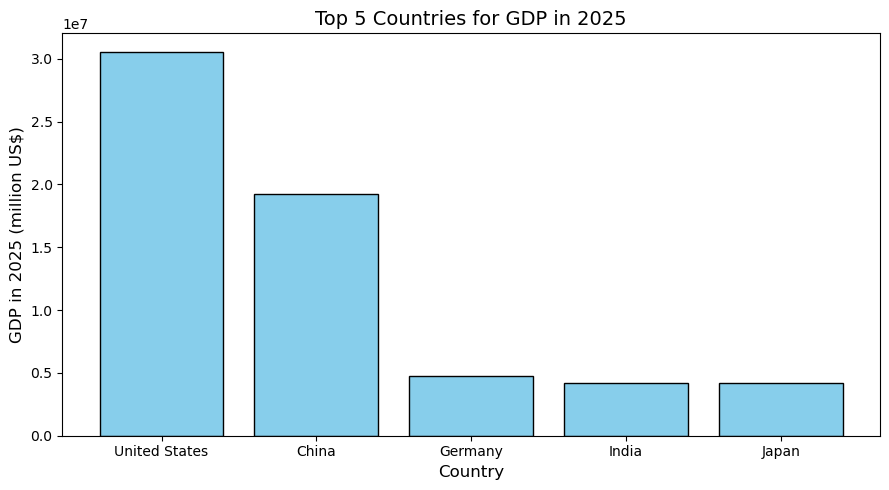

In [4]:
# Select the top 5 countries for GDP in 2025
top5 = df.dropna(subset=["2025"]).nlargest(5, "2025")
print(top5[["Country", "2025"]])

# Produce the bar chart
plt.figure(figsize=(9, 5))
plt.bar(top5["Country"], top5["2025"], color="skyblue", edgecolor="black")
plt.title("Top 5 Countries for GDP in 2025", fontsize=14)
plt.xlabel("Country", fontsize=12)
plt.ylabel("GDP in 2025 (million US$)", fontsize=12)
plt.tight_layout()
plt.show()

## Source

The dataset used in this notebook is GDP data published by the World Bank, provided as the file `2020-2025.csv` through Brightspace for this course.

[Source](https://data.worldbank.org/indicator/NY.GDP.MKTP.CD)